# Práctica de detección de objetos

### **Grupo:** N — **Integrantes:** Lucas Amado Oseira y María Lestón Geada
##### **Dataset:** Lettuce Pallets (`Francesco/lettuce-pallets` en Hugging Face)
##### **Detectores:** Cascade R-CNN (Detectron2) y SSD300-VGG16 (Torchvision), ambos preentrenados en MS COCO

## 0. Instalación del entorno

Ejecutamos esta celda una vez en una sesión nueva de Colab con GPU T4.
Si pide reiniciar la sesión, reiniciaremos y continuaremos desde la celda de imports.

In [1]:
# # Dependencias de evaluación y ensembles
# !pip -q install pycocotools ensemble-boxes

# # Detectron2 se compila desde el repositorio (tarda varios minutos)
#!pip -q install 'git+https://github.com/facebookresearch/detectron2.git' --no-build-isolation

Importamos las librerías necesarias para realizar la práctica.

In [2]:
import tarfile, random, torch, json, os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from PIL import Image

from datasets import load_dataset
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torch.utils.data import Dataset, DataLoader
import torchvision

Esta se realizará en Google Colab para garantizar la velocidad en la obtención de los resultados. Tambien definimos varias constantes: la ruta al zip que contiene los CSVs que utilizaremos, la ruta al directorio en el que se descomprimirá dicho zip y el dispositivo que se empleará en el entrenamiento. Además, fijaremos una semilla que nos garantice la reproducibilidad de los resultados.

In [3]:
SEED = 2710

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [4]:
# Descargar dataset desde Hugging Face
hf_ds = load_dataset("Francesco/lettuce-pallets")
print(hf_ds)

DATA_ROOT = Path("/kaggle/working/lettuce_pallets_coco")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

# Normalizar los nombres de splits (validation/valid -> val)
split_map = {}
for split_name in hf_ds.keys():
    s = split_name.lower()
    if s == "train": split_map["train"] = split_name
    elif "val" in s or "valid" in s: split_map["val"] = split_name
    elif "test" in s: split_map["test"] = split_name

print("Splits disponibles:", split_map)

README.md:   0%|          | 0.00/3.46k [00:00<?, ?B/s]

data/train-00000-of-00001-6677ec3fa20824(…): reconstructing file:   0%|          |  0.00B / 77.4MB            

data/train-00000-of-00001-6677ec3fa20824(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-7e4f3edd8(…): reconstructing file:   0%|          |  0.00B / 11.0MB            

data/validation-00000-of-00001-7e4f3edd8(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-fb3aeb2a5fe9d62(…): reconstructing file:   0%|          |  0.00B / 22.2MB            

data/test-00000-of-00001-fb3aeb2a5fe9d62(…): downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 1060
    })
    validation: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 151
    })
    test: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 299
    })
})
Splits disponibles: {'train': 'train', 'val': 'validation', 'test': 'test'}


In [5]:
# Exportar los splits a estructura COCO (imágenes + JSON de anotaciones)
ANN_FILES = {}
IMAGE_DIRS = {}

# Extraer nombres de categorías del feature ClassLabel, cuando esté disponible
cat_feature = hf_ds[next(iter(hf_ds.keys()))].features["objects"]["category"]
if hasattr(cat_feature, "names") and cat_feature.names:
    raw_class_names = list(cat_feature.names)
else:
    raw_class_names = None

# Obtener IDs de categorías observados en anotaciones
observed_categories = set()
for original_split in split_map.values():
    for row in hf_ds[original_split]:
        observed_categories.update(row["objects"]["category"])

observed_categories = sorted(int(c) for c in observed_categories)
if raw_class_names:
    CLASS_NAMES = [raw_class_names[c] for c in observed_categories]
else:
    CLASS_NAMES = [str(c) for c in observed_categories]

# COCO IDs 1..N; Torchvision/Detectron2 esperan IDs de clases positivos
category_id_map = {old_id: new_id for new_id, old_id in enumerate(observed_categories, start=1)}
cat_ids = list(category_id_map.values())
NUM_CLASSES = len(CLASS_NAMES)

for split, original_split in split_map.items():
    split_dir = DATA_ROOT / split
    image_dir = split_dir / "images"
    image_dir.mkdir(parents=True, exist_ok=True)
    images, annotations = [], []
    ann_id = 1

    for idx, row in enumerate(hf_ds[original_split]):
        img = row["image"].convert("RGB")
        file_name = f"{int(row.get('image_id', idx))}.jpg"
        img.save(image_dir / file_name, quality=95)
        image_id = int(idx)
        images.append({"id": image_id, "file_name": file_name,
                       "width": img.width, "height": img.height})

        objs = row["objects"]
        for bbox, old_cat in zip(objs["bbox"], objs["category"]):
            x, y, w, h = [float(v) for v in bbox]
            annotations.append({
                "id": ann_id, "image_id": image_id,
                "category_id": category_id_map[int(old_cat)],
                "bbox": [x, y, w, h], "area": w*h, "iscrowd": 0
            })
            ann_id += 1

    categories = [{"id": category_id_map[old_id], "name": name}
                  for old_id, name in zip(observed_categories, CLASS_NAMES)]
    coco_json = {"images": images, "annotations": annotations, "categories": categories}
    ann_file = split_dir / "annotations.json"
    with open(ann_file, "w") as f:
        json.dump(coco_json, f)

    ANN_FILES[split] = ann_file
    IMAGE_DIRS[split] = image_dir

print("Splits exportados:", list(ANN_FILES))
print("Categorías:", list(zip(cat_ids, CLASS_NAMES)))
print("Número de clases:", NUM_CLASSES)


Splits exportados: ['train', 'val', 'test']
Categorías: [(1, '1'), (2, '2'), (3, '3'), (4, '4'), (5, '5')]
Número de clases: 5


A continuación, cargamos el dataset de entrenamiento COCO y mostramos información sobre las distintas categorías de lechuga y las anotaciones existentes para cada imagen.

In [6]:
coco_train = COCO(str(ANN_FILES["train"]))
cats = sorted(coco_train.loadCats(coco_train.getCatIds()), key=lambda x: x["id"])

print(f"\nCategorías COCO:", [(c["id"], c["name"]) for c in cats])
print(f"Total imágenes de entrenamiento: {len(coco_train.getImgIds())}")
print(f"Número de anotaciones train: {len(coco_train.getAnnIds())}")

CLASS_NAMES = [ c["name"] for c in cats ]
CLASS_IDS = [ c["id"] for c in cats ]
NUM_CLASSES = len(CLASS_NAMES)

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!

Categorías COCO: [(1, '1'), (2, '2'), (3, '3'), (4, '4'), (5, '5')]
Total imágenes de entrenamiento: 1060
Número de anotaciones train: 13812


En principio vemos que existen 6 categorías distintas: *'lettuce', 'Ready', 'empty_pod', 'germination', 'pod'* y *'young'*, repartidas entre 1060 imágenes de entrenamiento y con un total de 13812 anotaciones.

Lo siguiente que haremos será mostrar algunas de estas imágenes de entrenamiento con sus respectivas anotaciones.

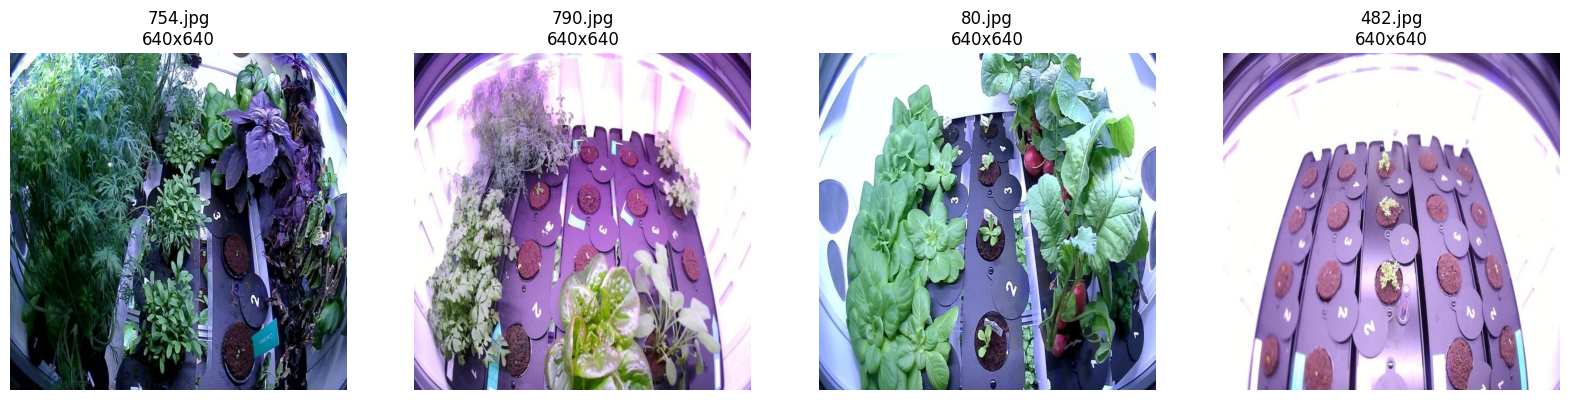

In [7]:
def show_coco(coco, image_dir, n=4):
    ids = random.sample(coco.getImgIds(), min(n, len(coco.getImgIds())))
    fig, axs = plt.subplots(1, len(ids), figsize=(5*len(ids), 5))
    if len(ids) == 1:
        axs = [axs]
    for ax, img_id in zip(axs, ids):
        img_info = coco.loadImgs(img_id)[0]
        img_path = image_dir / img_info["file_name"]
        img = plt.imread(img_path)
        ax.imshow(img)
        ax.set_title(f"{img_info['file_name']}\n{img_info['width']}x{img_info['height']}")
        ax.axis("off")
    plt.show()

show_coco(coco_train, IMAGE_DIRS["train"], n=4)

Seguidamente, creamos una clase que cargue el dataset COCO y prepare los datos tanto para entrenamiento como para evaluación.

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Downloading: "https://download.pytorch.org/models/ssd300_vgg16_coco-b556d3b4.pth" to /root/.cache/torch/hub/checkpoints/ssd300_vgg16_coco-b556d3b4.pth


100%|██████████| 136M/136M [00:00<00:00, 171MB/s]  


SSD300 preparado correctamente.
SSD epoch 1/15: train=3.7895 val=2.7065
SSD epoch 2/15: train=2.3194 val=2.1903
SSD epoch 3/15: train=1.9103 val=2.0760
SSD epoch 4/15: train=1.6495 val=1.8703
SSD epoch 5/15: train=1.4627 val=1.8137
SSD epoch 6/15: train=1.1116 val=1.7009
SSD epoch 7/15: train=1.0531 val=1.6992
SSD epoch 8/15: train=1.0142 val=1.7078
SSD epoch 9/15: train=0.9861 val=1.7058
SSD epoch 10/15: train=0.9550 val=1.7176
SSD epoch 11/15: train=0.9155 val=1.7159
SSD epoch 12/15: train=0.9128 val=1.7194
SSD epoch 13/15: train=0.9104 val=1.7181
SSD epoch 14/15: train=0.9066 val=1.7210
SSD epoch 15/15: train=0.9063 val=1.7237


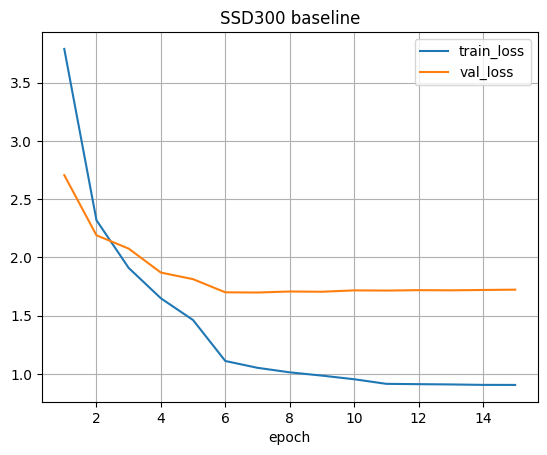

In [8]:
class CocoDetection(Dataset):
    def __init__(self, ann_file, image_dir, train=False):
        self.coco = COCO(str(ann_file))
        self.image_dir = Path(image_dir)
        self.ids = list(sorted(self.coco.getImgIds()))
        self.train = train

    def __len__(self):
        return len(self.ids)

    def _image_path(self, file_name):
        p = self.image_dir / file_name
        if p.exists():
            return p
        else:
            raise FileNotFoundError(f"Image file not found: {p}")

    def __getitem__(self, index):
        img_id = self.ids[index]
        img_info = self.coco.loadImgs(img_id)[0]
        image = Image.open(self._image_path(img_info["file_name"])).convert("RGB")
        image = torchvision.transforms.functional.to_tensor(image)

        ann_ids = self.coco.getAnnIds(imgIds=[img_id])
        anns = self.coco.loadAnns(ann_ids)

        boxes = []
        labels = []

        for ann in anns:
            x, y, w, h = ann["bbox"]
        
            boxes.append([
                x,
                y,
                x + w,
                y + h
            ])
        
            labels.append(ann["category_id"])

        boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([image_id], dtype=torch.int64),
        }

        if self.train:
            # Apply any data augmentation here if needed
            pass

        return image, target

def collate_fn(batch):
    return tuple(zip(*batch))

# Creamos los DataLoaders para entrenamiento y validación, que servirán para alimentar el modelo durante el entrenamiento y la evaluación
# Se utiliza un tamaño de batch de 4 y se aplica la función de colación personalizada para manejar los datos de manera adecuada
train_ds = CocoDetection(ANN_FILES["train"], IMAGE_DIRS["train"], train=True)
val_ds = CocoDetection(ANN_FILES["val"], IMAGE_DIRS["val"], train=False)
test_ds = CocoDetection(ANN_FILES["test"], IMAGE_DIRS["test"], train=False)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, collate_fn=collate_fn)

# Una vez creados los DataLoaders procedemos a construir el detector SSD300 con VGG16 como backbone, utilizando pesos preentrenados en COCO y adaptando la cabeza de clasificación para nuestras clases específicas.

from torchvision.models.detection import ssd300_vgg16
from torchvision.models.detection import SSD300_VGG16_Weights
from torchvision.models.detection.ssd import SSDClassificationHead

def build_ssd(pretrained=True):
    weights = SSD300_VGG16_Weights.COCO_V1 if pretrained else None
    model = ssd300_vgg16(weights=weights)

    # Obtener los canales de entrada de cada capa directamente
    old_head = model.head.classification_head
    in_channels = [
        layer.in_channels for layer in old_head.module_list
    ]

    # Número de anchors por cada nivel de características
    num_anchors = model.anchor_generator.num_anchors_per_location()

    # Sustituir cabeza de clasificación para nuestras clases
    model.head.classification_head = SSDClassificationHead(
        in_channels=in_channels,
        num_anchors=num_anchors,
        num_classes=NUM_CLASSES + 1  # +1 para fondo
    )

    return model

ssd = build_ssd(pretrained=True).to(DEVICE)

print("SSD300 preparado correctamente.")

def train_one_epoch(model, loader, optimizer, device):
    model.train(); losses=[]
    for images, targets in loader:
        images = [im.to(device) for im in images]
        targets = [{k:v.to(device) for k,v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())
        optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        optimizer.step()
        losses.append(float(loss.detach().cpu()))
    return float(np.mean(losses))

@torch.no_grad()
def mean_detection_loss(model, loader, device):
    # Torchvision calcula loss solo en modo train; no actualizar gradientes.
    model.train(); vals=[]
    for images, targets in loader:
        images=[im.to(device) for im in images]
        targets=[{k:v.to(device) for k,v in t.items()} for t in targets]
        ld=model(images,targets); vals.append(float(sum(ld.values()).cpu()))
    model.eval()
    return float(np.mean(vals))

EPOCHS_SSD = 15
optimizer = torch.optim.SGD([p for p in ssd.parameters() if p.requires_grad],
                            lr=0.002, momentum=0.9, weight_decay=0.0005)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
history_ssd=[]
best_val=float("inf")
for epoch in range(EPOCHS_SSD):
    tr=train_one_epoch(ssd,train_loader,optimizer,DEVICE)
    vl=mean_detection_loss(ssd,val_loader,DEVICE)
    scheduler.step()
    history_ssd.append({"epoch":epoch+1,"train_loss":tr,"val_loss":vl})
    print(f"SSD epoch {epoch+1}/{EPOCHS_SSD}: train={tr:.4f} val={vl:.4f}")
    if vl < best_val:
        best_val=vl
        torch.save(ssd.state_dict(),"ssd300_baseline_best.pth")
ssd.load_state_dict(torch.load("ssd300_baseline_best.pth",map_location=DEVICE))
ssd.eval()
pd.DataFrame(history_ssd).plot(x="epoch",y=["train_loss","val_loss"],grid=True,title="SSD300 baseline")
plt.show()



In [9]:
!pip install 'git+https://github.com/facebookresearch/detectron2.git' --no-build-isolation

  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-psequwjh
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-psequwjh
  Resolved https://github.com/facebookresearch/detectron2.git to commit 247691a1c292654867deb35cabb27f18d75a1363
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for detectron2: filename=detectron2-0.6-cp313-cp313-linux_x86_64.whl size=7052680 sha256=1bb051221042d24ae10ff670c129702bacd69ee56c8e0748fb90b86b0208ca2f
  Stored in directory: /tmp/pip-ephem-wheel-cache-yys0k4yu/wheels/d9/ed/56/4ffdb2ce244e0d6ed6c0916db7f7a74254f74435fea7142143
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61443 sha256=05a944e2bf2593f3f57ad792a5b6881e0b532999bd11e8102a0d24a9509a026f
  Stored in directory: /root/.cache/pip/wheels/6b/1b/9a/9f484

In [10]:
# Esta celda requiere detectron2 instalado correctamente.
from detectron2.data.datasets import register_coco_instances
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader

for split in ("train","val","test"):
    if split in ANN_FILES and split in IMAGE_DIRS:
        name=f"lettuce_{split}"
        if name in DatasetCatalog.list(): DatasetCatalog.remove(name)
        register_coco_instances(name, {}, str(ANN_FILES[split]), str(IMAGE_DIRS[split]))
        MetadataCatalog.get(name).set(thing_classes=CLASS_NAMES)

CASCADE_CONFIG = "Misc/cascade_mask_rcnn_R_50_FPN_3x.yaml"
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CASCADE_CONFIG))
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CASCADE_CONFIG)
cfg.MODEL.MASK_ON = False
cfg.DATASETS.TRAIN = ("lettuce_train",)
cfg.DATASETS.TEST = ("lettuce_val",)
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.ROI_HEADS.NUM_CLASSES = NUM_CLASSES
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = max(500, len(train_ds)//2 * 10)
cfg.SOLVER.STEPS = (int(cfg.SOLVER.MAX_ITER*0.7), int(cfg.SOLVER.MAX_ITER*0.9))
cfg.SOLVER.CHECKPOINT_PERIOD = max(100, cfg.SOLVER.MAX_ITER//3)
cfg.TEST.EVAL_PERIOD = max(100, cfg.SOLVER.MAX_ITER//5)
cfg.OUTPUT_DIR = "./output_cascade_baseline"
os.makedirs(cfg.OUTPUT_DIR,exist_ok=True)
# Evita sobrescribir configuración con valores previos del entorno.
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


[11/24 15:33:45 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

model_final_480dd8.pkl: 288MB [00:05, 57.7MB/s]                              
Skip loading parameter 'roi_heads.box_predictor.0.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (6, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.0.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (6,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.1.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (6, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.1.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (6,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.2.cls_score.weight' to the

[11/24 15:33:51 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1124 15:33:53.220000 49 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


[11/24 15:34:05 d2.utils.events]:  eta: 0:54:30  iter: 19  total_loss: 7.64  loss_cls_stage0: 1.626  loss_box_reg_stage0: 0.6858  loss_cls_stage1: 1.859  loss_box_reg_stage1: 0.7671  loss_cls_stage2: 1.912  loss_box_reg_stage2: 0.3284  loss_rpn_cls: 0.3228  loss_rpn_loc: 0.1092    time: 0.6133  last_time: 0.6398  data_time: 0.0137  last_data_time: 0.0068   lr: 4.9953e-06  max_mem: 2345M


I0000 00:00:1795534464.849625      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


[11/24 15:34:39 d2.utils.events]:  eta: 0:54:24  iter: 39  total_loss: 7.557  loss_cls_stage0: 1.561  loss_box_reg_stage0: 0.6644  loss_cls_stage1: 1.808  loss_box_reg_stage1: 0.7547  loss_cls_stage2: 1.829  loss_box_reg_stage2: 0.4456  loss_rpn_cls: 0.3282  loss_rpn_loc: 0.0959    time: 0.6169  last_time: 0.7069  data_time: 0.0063  last_data_time: 0.0053   lr: 9.9902e-06  max_mem: 2346M
[11/24 15:34:53 d2.utils.events]:  eta: 0:55:55  iter: 59  total_loss: 7.001  loss_cls_stage0: 1.429  loss_box_reg_stage0: 0.6322  loss_cls_stage1: 1.675  loss_box_reg_stage1: 0.7487  loss_cls_stage2: 1.661  loss_box_reg_stage2: 0.4634  loss_rpn_cls: 0.2947  loss_rpn_loc: 0.09063    time: 0.6337  last_time: 0.5979  data_time: 0.0066  last_data_time: 0.0063   lr: 1.4985e-05  max_mem: 2346M
[11/24 15:35:05 d2.utils.events]:  eta: 0:55:47  iter: 79  total_loss: 6.289  loss_cls_stage0: 1.298  loss_box_reg_stage0: 0.5688  loss_cls_stage1: 1.506  loss_box_reg_stage1: 0.8302  loss_cls_stage2: 1.457  loss_box_

In [11]:
# Evaluación de Cascade R-CNN
# Esta celda depende de la celda anterior (configuración y entrenamiento de Detectron2).

if "cfg" not in globals():
    raise RuntimeError("No existe cfg. Ejecuta primero la celda de configuración/entrenamiento de Cascade R-CNN (celda 20).")

checkpoint_path = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")
if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(f"No se encontró {checkpoint_path}. Ejecuta primero el entrenamiento de Cascade R-CNN y asegúrate de que finalice.")

def evaluate_detectron2(cfg, split="val"):
    evaluator = COCOEvaluator(f"lettuce_{split}", output_dir=cfg.OUTPUT_DIR)
    loader = build_detection_test_loader(cfg, f"lettuce_{split}")
    predictor = DefaultPredictor(cfg)
    return inference_on_dataset(predictor.model, loader, evaluator)

# Cargar pesos finales y evaluar
cfg.MODEL.WEIGHTS = checkpoint_path
cascade_results = evaluate_detectron2(cfg, "val")
print(cascade_results)


[11/24 16:30:09 d2.data.datasets.coco]: Loaded 151 images in COCO format from /kaggle/working/lettuce_pallets_coco/val/annotations.json
[11/24 16:30:09 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[11/24 16:30:09 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[11/24 16:30:09 d2.data.common]: Serializing 151 elements to byte tensors and concatenating them all ...
[11/24 16:30:09 d2.data.common]: Serialized dataset takes 0.14 MiB
[11/24 16:30:10 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_cascade_baseline/model_final.pth ...
[11/24 16:30:11 d2.evaluation.evaluator]: Start inference on 151 batches
[11/24 16:30:13 d2.evaluation.evaluator]: Inference done 11/151. Dataloading: 0.0019 s/iter. Inference: 0.1680 s/iter. Eval: 0.0004 s/iter. Total: 0.1702 s/iter. ETA=0:00:23
[11/24 16:30

In [12]:
@torch.no_grad()
def torchvision_predictions_to_coco(model, dataset, score_thresh=0.001):
    model.eval(); predictions=[]
    loader=DataLoader(dataset,batch_size=2,shuffle=False,num_workers=2,collate_fn=collate_fn)
    for images, targets in loader:
        outputs=model([im.to(DEVICE) for im in images])
        for target,out in zip(targets,outputs):
            image_id=int(target["image_id"].item())
            for box,score,label in zip(out["boxes"].cpu(),out["scores"].cpu(),out["labels"].cpu()):
                if float(score)<score_thresh: continue
                x1,y1,x2,y2=map(float,box.tolist())
                contig=int(label)-1
                if contig<0 or contig>=NUM_CLASSES: continue
                predictions.append({"image_id":image_id,"category_id":cat_ids[contig],
                                    "bbox":[x1,y1,max(0,x2-x1),max(0,y2-y1)],
                                    "score":float(score)})
    return predictions

def coco_metrics(coco_gt, predictions):
    if not predictions:
        return {"mAP50":0.0,"mAP50_95":0.0}
    coco_dt=coco_gt.loadRes(predictions)
    ev=COCOeval(coco_gt,coco_dt,"bbox")
    ev.evaluate(); ev.accumulate(); ev.summarize()
    return {"mAP50_95":float(ev.stats[0]),"mAP50":float(ev.stats[1])}

coco_val=COCO(str(ANN_FILES["val"]))
ssd_val_preds=torchvision_predictions_to_coco(ssd,val_ds)
ssd_val_metrics=coco_metrics(coco_val,ssd_val_preds)
print("SSD300 validation:",ssd_val_metrics)

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loading and preparing results...


AssertionError: Results do not correspond to current coco set

In [ ]:
coco_val = COCO(str(ANN_FILES["val"]))

gt_ids = set(coco_val.getImgIds())
pred_ids = {int(p["image_id"]) for p in ssd_val_preds}

print("Imágenes COCO validation:", len(gt_ids))
print("Imágenes en predicciones:", len(pred_ids))
print("IDs que sobran:", sorted(pred_ids - gt_ids)[:20])
print("IDs que faltan:", sorted(gt_ids - pred_ids)[:20])

In [ ]:
print("Tamaño val_ds:", len(val_ds))
print("Tamaño val_loader:", len(val_loader))

print("\nPrimeros elementos del dataset:")
for i in range(min(5, len(val_ds))):
    image, target = val_ds[i]
    print(
        i,
        "image_id:", target.get("image_id"),
        "boxes:", target["boxes"].shape,
        "labels:", target["labels"].shape
    )

print("\nNúmero de batches:", len(val_loader))